# Customer Churn Prediction and Retention Segmentation
## Machine Learning Lab (Practical 10) - TY Computer Engineering
**Academic Year:** 2026-2027  
**Objective:** End-to-end Machine Learning pipeline to predict customer churn in telecommunications and segment at-risk subscribers to formulate targeted retention strategies.


---
## 1. Problem Statement, Objectives, and Business Impact

### 1.1 The Business Problem
In subscription-based telecommunication markets, customer churn (switching to a rival provider) is one of the most critical threats to recurring revenue. Because customer acquisition costs (**CAC**) are typically 5 to 7 times higher than customer retention costs (**CRC**), even a modest 5% reduction in churn can boost operating profits significantly.

### 1.2 Objectives
1. **Supervised Churn Classification:** Predict whether an individual subscriber will leave (`Churn = Yes`) using machine learning classifiers.
2. **Handle Class Imbalance:** Mitigate the natural imbalance (~73% retained vs ~27% churned) using synthetic sampling (SMOTE) to avoid deceptive high accuracy with poor recall.
3. **Interpretability & Model Explainability:** Identify the primary churn drivers using SHAP values and model feature attributions.
4. **Unsupervised Retention Segmentation:** Micro-segment high-risk customers using K-Means and Gaussian Mixture Models (GMM) with PCA visualization.
5. **Business Recommendations & Financial ROI:** Prescribe tailored retention actions per segment and calculate estimated revenue saved.

### 1.3 Why We Do This
> **Student Note:** Rather than treating churn as a simple binary prediction, modern data science combines *predictive modeling* (who will leave?) with *unsupervised clustering* (why are they leaving and how should we treat them?). This bridges the gap between raw statistical output and actionable business strategy.


In [1]:
# Import standard data science libraries
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Set global aesthetics and seeds
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

# Ensure robust path resolution regardless of execution working directory
current_dir = os.getcwd()
if os.path.basename(current_dir) == 'notebooks':
    BASE_DIR = os.path.abspath('..')
else:
    BASE_DIR = os.path.abspath('.')

DATA_PATH = os.path.join(BASE_DIR, 'data', 'WA_Fn-UseC_-Telco-Customer-Churn.csv')
FIG_DIR = os.path.join(BASE_DIR, 'outputs', 'figures')
MODEL_DIR = os.path.join(BASE_DIR, 'models')

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
print(f"Environment initialized. Project root: {BASE_DIR}")
print(f"Figures directory: {FIG_DIR}")
print(f"Models directory:  {MODEL_DIR}")


Environment initialized. Project root: C:\Users\Nomaan\OneDrive\Desktop\MlProject
Figures directory: C:\Users\Nomaan\OneDrive\Desktop\MlProject\outputs\figures
Models directory:  C:\Users\Nomaan\OneDrive\Desktop\MlProject\models


---
## 2. Exploratory Data Analysis (EDA)

### Why We Do This:
Before training any model, exploratory data analysis is essential to understand feature distributions, uncover hidden relationships with churn, and detect data quality issues (such as missing values or non-standard encodings).

We will generate and save at least **6 key visualizations**:
1. Target Churn Distribution
2. Churn Rate across Contract Types
3. Churn Distribution across Customer Tenure
4. Monthly Charges Distribution by Churn Status
5. Churn Rate across Internet Service Types
6. Churn Rate across Payment Methods
7. Correlation Heatmap of Numeric & Encoded Features


In [2]:
# Load the dataset
data_path = DATA_PATH
df_raw = pd.read_csv(data_path)

print(f"Dataset Dimensions: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print("\nFirst 3 rows:")
df_raw.head(3)


Dataset Dimensions: 7043 rows, 21 columns

First 3 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [3]:
# Dataset info & data types
print("Summary of data types and non-null values:")
df_raw.info()


Summary of data types and non-null values:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessB

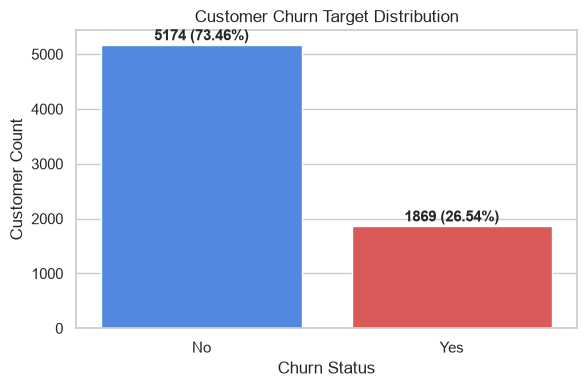

In [4]:
# 1. Churn Distribution (Target Variable)
fig, ax = plt.subplots(figsize=(6, 4))
churn_counts = df_raw['Churn'].value_counts()
churn_pct = (churn_counts / len(df_raw) * 100).round(2)

sns.barplot(x=churn_counts.index, y=churn_counts.values, palette=["#3B82F6", "#EF4444"], ax=ax)
for i, v in enumerate(churn_counts.values):
    ax.text(i, v + 80, f"{v} ({churn_pct.iloc[i]}%)", ha='center', fontweight='bold')

ax.set_title("Customer Churn Target Distribution")
ax.set_ylabel("Customer Count")
ax.set_xlabel("Churn Status")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "churn_distribution.png"), dpi=300)
plt.show()


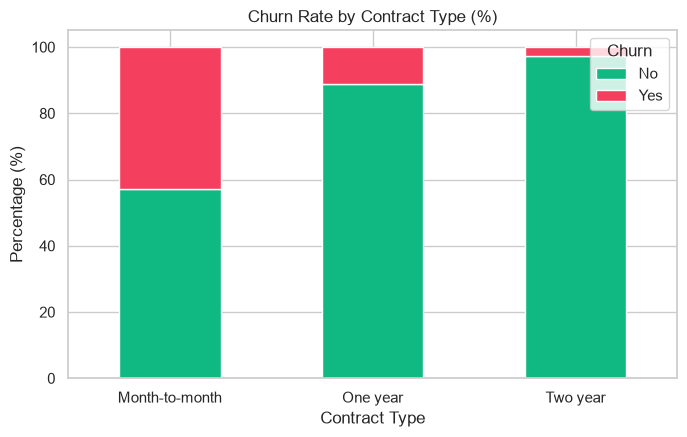

In [5]:
# 2. Churn vs Contract Type
fig, ax = plt.subplots(figsize=(7, 4.5))
contract_churn = pd.crosstab(df_raw['Contract'], df_raw['Churn'], normalize='index') * 100

contract_churn.plot(kind='bar', stacked=True, color=["#10B981", "#F43F5E"], ax=ax)
ax.set_title("Churn Rate by Contract Type (%)")
ax.set_ylabel("Percentage (%)")
ax.set_xlabel("Contract Type")
ax.legend(title="Churn", loc="upper right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "churn_vs_contract.png"), dpi=300)
plt.show()


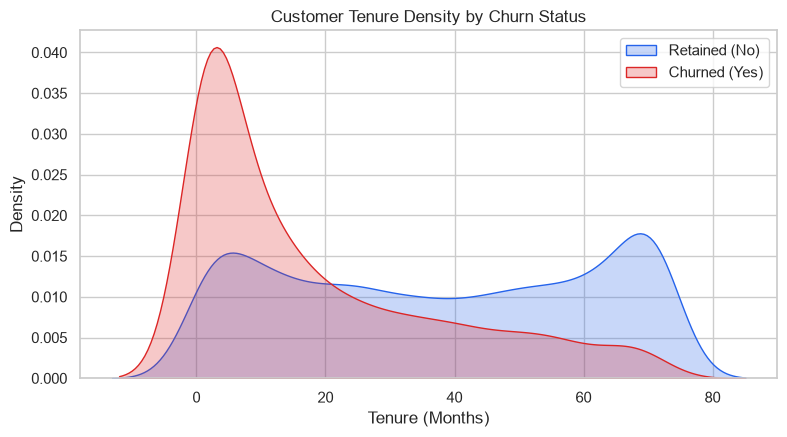

In [6]:
# 3. Churn vs Customer Tenure (Months)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.kdeplot(data=df_raw[df_raw['Churn'] == 'No']['tenure'], label='Retained (No)', shade=True, color='#2563EB')
sns.kdeplot(data=df_raw[df_raw['Churn'] == 'Yes']['tenure'], label='Churned (Yes)', shade=True, color='#DC2626')
ax.set_title("Customer Tenure Density by Churn Status")
ax.set_xlabel("Tenure (Months)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "churn_vs_tenure.png"), dpi=300)
plt.show()


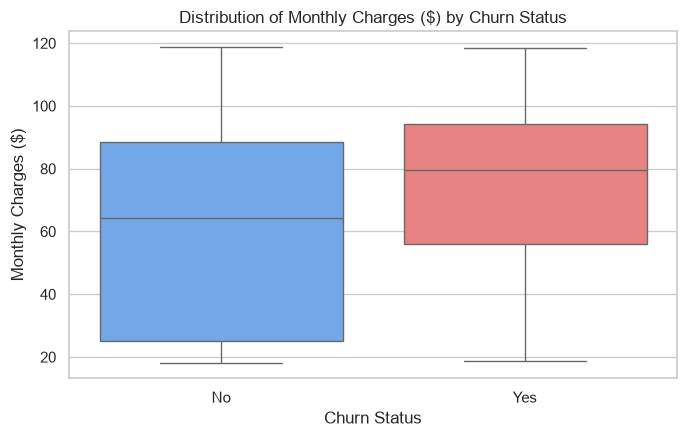

In [7]:
# 4. Monthly Charges by Churn Status
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df_raw, x='Churn', y='MonthlyCharges', palette=["#60A5FA", "#F87171"], ax=ax)
ax.set_title("Distribution of Monthly Charges ($) by Churn Status")
ax.set_xlabel("Churn Status")
ax.set_ylabel("Monthly Charges ($)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "churn_vs_monthly_charges.png"), dpi=300)
plt.show()


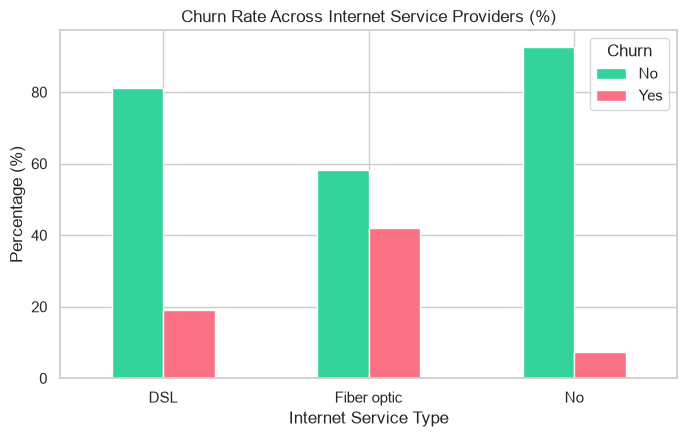

In [8]:
# 5. Churn vs Internet Service Provider Type
fig, ax = plt.subplots(figsize=(7, 4.5))
internet_churn = pd.crosstab(df_raw['InternetService'], df_raw['Churn'], normalize='index') * 100
internet_churn.plot(kind='bar', color=["#34D399", "#FB7185"], ax=ax)
ax.set_title("Churn Rate Across Internet Service Providers (%)")
ax.set_ylabel("Percentage (%)")
ax.set_xlabel("Internet Service Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "churn_vs_internet_service.png"), dpi=300)
plt.show()


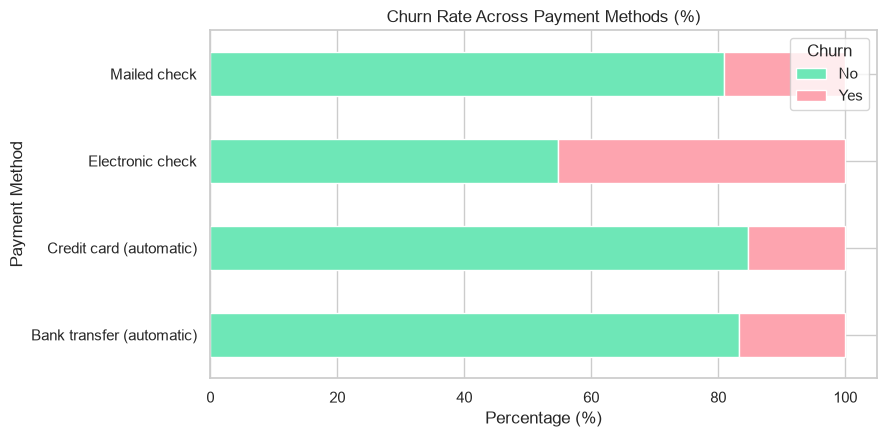

In [9]:
# 6. Churn vs Payment Method
fig, ax = plt.subplots(figsize=(9, 4.5))
payment_churn = pd.crosstab(df_raw['PaymentMethod'], df_raw['Churn'], normalize='index') * 100
payment_churn.plot(kind='barh', stacked=True, color=["#6EE7B7", "#FDA4AF"], ax=ax)
ax.set_title("Churn Rate Across Payment Methods (%)")
ax.set_xlabel("Percentage (%)")
ax.set_ylabel("Payment Method")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "churn_vs_payment_method.png"), dpi=300)
plt.show()


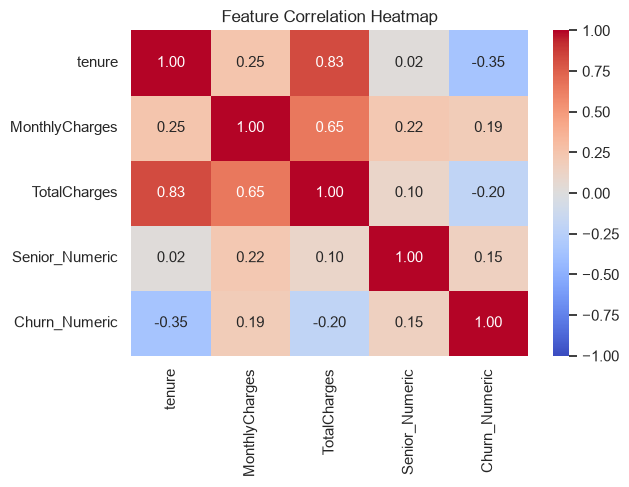

In [10]:
# 7. Correlation Heatmap of Numeric & Binary Attributes
df_eda = df_raw.copy()
# Convert whitespace in TotalCharges to numeric
df_eda['TotalCharges'] = pd.to_numeric(df_eda['TotalCharges'].astype(str).str.strip(), errors='coerce').fillna(0)
df_eda['Churn_Numeric'] = df_eda['Churn'].map({'Yes': 1, 'No': 0})
df_eda['Senior_Numeric'] = df_eda['SeniorCitizen']

corr_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Senior_Numeric', 'Churn_Numeric']
corr_matrix = df_eda[corr_cols].corr()

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, ax=ax)
ax.set_title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "correlation_heatmap.png"), dpi=300)
plt.show()


---
## 3. Data Preprocessing & Anti-Leakage Pipeline

### Why We Do This:
1. **Handling Whitespace Strings in `TotalCharges`:** 11 customers have a tenure of 0 months (new signups), and their `TotalCharges` was entered as `" "`. We parse them as numeric and impute with 0.0.
2. **Dropping Identifiers:** `customerID` is an arbitrary identifier and offers no predictive signal.
3. **Encoding Categorical Features:** Binary flags (e.g. Partner, Dependents) and multi-class categories (Contract, InternetService) are converted via One-Hot Encoding.
4. **Feature Scaling:** Distance- and gradient-based models (SVM, k-NN, Logistic Regression) are sensitive to feature scales. Numeric features (`tenure`, `MonthlyCharges`, `TotalCharges`) are scaled with `StandardScaler`.
5. **Anti-Leakage Partitioning:** To guarantee strict real-world generalization, we perform a Stratified Train-Test Split (80/20) first. All transformations are fitted strictly on `X_train`.


In [11]:
# Clean raw dataset
df_clean = df_raw.copy()

# 1. Drop customerID
if 'customerID' in df_clean.columns:
    df_clean.drop(columns=['customerID'], inplace=True)

# 2. Convert TotalCharges whitespace to float
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'].astype(str).str.strip(), errors='coerce').fillna(0.0)

# 3. Format SeniorCitizen
df_clean['SeniorCitizen'] = df_clean['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

print(f"Data cleaned. Total missing values: {df_clean.isnull().sum().sum()}")


Data cleaned. Total missing values: 0


---
## 4. Feature Engineering

### Why We Do This:
Domain-specific features enhance algorithm representations:
1. `tenure_group`: Discretizes tenure into lifecycle segments (`0-12m`, `13-24m`, `25-48m`, `49-60m`, `>60m`).
2. `avg_monthly_spend`: Historical spend efficiency `TotalCharges / (tenure + 1)`.
3. `num_services`: Sum of active services (telephony, security, streaming, backup). Customers with multiple bundled services exhibit higher switching costs (stickiness).
4. `has_support_services`: Compound flag indicating if the subscriber has Tech Support or Online Security.


In [12]:
# 1. Tenure Groups
bins = [-1, 12, 24, 48, 60, np.inf]
labels = ['0-12m', '13-24m', '25-48m', '49-60m', '>60m']
df_clean['tenure_group'] = pd.cut(df_clean['tenure'], bins=bins, labels=labels)

# 2. Average Monthly Spend
df_clean['avg_monthly_spend'] = (df_clean['TotalCharges'] / (df_clean['tenure'] + 1)).round(2)

# 3. Number of Services
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
count_services = pd.Series(0, index=df_clean.index)
for col in service_cols:
    count_services += (df_clean[col] == 'Yes').astype(int)
count_services += (df_clean['InternetService'].isin(['DSL', 'Fiber optic'])).astype(int)
df_clean['num_services'] = count_services

# 4. Support Services Flag
has_tech = (df_clean['TechSupport'] == 'Yes')
has_sec = (df_clean['OnlineSecurity'] == 'Yes')
df_clean['has_support_services'] = (has_tech | has_sec).map({True: 'Yes', False: 'No'})

print("Engineered features preview:")
df_clean[['tenure', 'tenure_group', 'MonthlyCharges', 'avg_monthly_spend', 'num_services', 'has_support_services']].head()


Engineered features preview:


,tenure,tenure_group,MonthlyCharges,avg_monthly_spend,num_services,has_support_services
0,1,0-12m,29.85,14.92,2,No
1,34,25-48m,56.95,53.99,4,Yes
2,2,0-12m,53.85,36.05,4,Yes
3,45,25-48m,42.30,40.02,4,Yes
4,2,0-12m,70.70,50.55,2,No


In [13]:
# Split into Features X and Target y
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

y = df_clean['Churn'].map({'Yes': 1, 'No': 0}).astype(int)
X = df_clean.drop(columns=['Churn'])

# Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples (Churn rate: {y_train.mean():.2%})")
print(f"Testing set:  {X_test.shape[0]} samples (Churn rate: {y_test.mean():.2%})")

# Construct ColumnTransformer Preprocessor
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='drop'
)
print(f"Identified {len(numeric_features)} numeric features and {len(categorical_features)} categorical features.")


Training set: 5634 samples (Churn rate: 26.54%)
Testing set:  1409 samples (Churn rate: 26.54%)
Identified 5 numeric features and 18 categorical features.


---
## 5. Class Imbalance Handling (SMOTE)

### Why We Do This:
The dataset is imbalanced (~73.5% retain, ~26.5% churn). In telecom business, a **False Negative** (failing to catch a churner) leads directly to lost revenue. If trained on raw imbalanced data, models often achieve high nominal accuracy by predicting "No Churn" but suffer poor recall on churners.

We apply **SMOTE (Synthetic Minority Over-sampling Technique)**, which synthesizes new minority class instances along line segments joining k-nearest neighbors.
> **Critical Rule:** SMOTE is integrated within an `imblearn.pipeline.Pipeline`. This ensures SMOTE is applied **only to the training folds** during cross-validation, strictly preventing data leakage into validation or testing sets.


---
## 6. Supervised Model Building with Hyperparameter Tuning

We implement and tune four diverse supervised algorithms:
1. **Logistic Regression (Baseline):** Probabilistic linear classifier modeling log-odds.
2. **Support Vector Machine (SVM):** Non-linear kernel boundary classifier (RBF kernel).
3. **k-Nearest Neighbors (k-NN):** Instance-based metric learner (with systematic analysis of $k$ on performance).
4. **Gradient Boosting:** Sequential ensemble of decision trees optimizing residual loss.

We tune hyperparameters using **5-fold Stratified Cross-Validation** optimizing for **ROC-AUC**.


In [14]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 1. Logistic Regression
pipe_lr = ImbPipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
grid_lr = GridSearchCV(
    pipe_lr,
    param_grid={'classifier__C': [0.01, 0.1, 1.0, 10.0]},
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)
grid_lr.fit(X_train, y_train)
print(f"Logistic Regression Best Params: {grid_lr.best_params_} (ROC-AUC: {grid_lr.best_score_:.4f})")


Logistic Regression Best Params: {'classifier__C': 0.1} (ROC-AUC: 0.8468)


In [15]:
# 2. Support Vector Machine (SVM)
pipe_svm = ImbPipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('classifier', SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE))
])
grid_svm = GridSearchCV(
    pipe_svm,
    param_grid={'classifier__C': [0.5, 1.0, 2.0]},
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)
grid_svm.fit(X_train, y_train)
print(f"SVM Best Params: {grid_svm.best_params_} (ROC-AUC: {grid_svm.best_score_:.4f})")


SVM Best Params: {'classifier__C': 0.5} (ROC-AUC: 0.8321)


Evaluating k-NN hyperparameter K from 3 to 81 via 5-fold CV strictly on X_train...



k-NN 5-Fold Cross-Validation Scores (Training Set Only, sample view):
 k  Mean_CV_ROC_AUC  Std_CV_ROC_AUC
 3         0.732174        0.012284
 5         0.767958        0.013917
 7         0.782172        0.013471
 9         0.794074        0.010137
11         0.797336        0.008458
73         0.835908        0.011628
75         0.836411        0.012124
77         0.836327        0.012503
79         0.836814        0.012361
81         0.837045        0.012571

Optimal K selected via Training CV: K = 81 (Mean CV ROC-AUC: 0.8370)
Note: CV ROC-AUC plateaus around K=73-81 (0.8359 to 0.8370), so K=81 is near the edge of the search range.


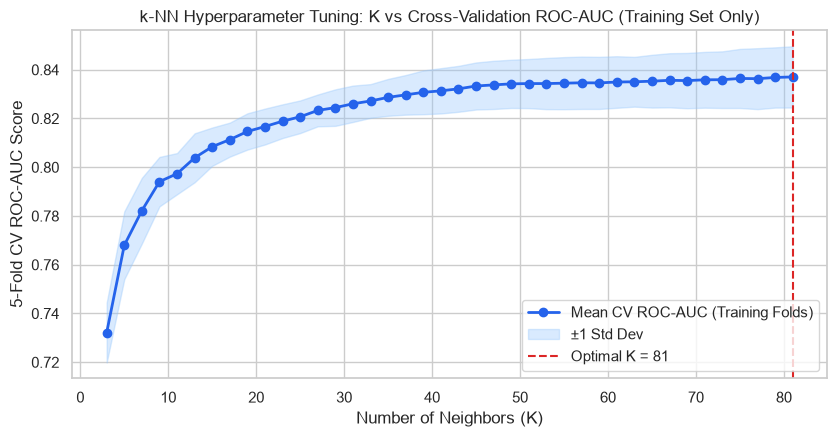

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](23,)","['gender','SeniorCitizen','Partner',...,'avg_monthly_spend','num_services', 'has_support_services']"
n_features_in_,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [16]:
# 3. k-NN Hyperparameter Tuning via Cross-Validation on Training Set ONLY
from sklearn.model_selection import cross_val_score

# Evaluate K across extended range 3 to 81 using odd integers on the training set only
k_range = list(range(3, 82, 2))
knn_cv_scores = []

print("Evaluating k-NN hyperparameter K from 3 to 81 via 5-fold CV strictly on X_train...")
for k in k_range:
    pipe_knn_k = ImbPipeline([
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('classifier', KNeighborsClassifier(n_neighbors=k))
    ])
    # Cross-validation strictly on training set to avoid data leakage
    scores = cross_val_score(pipe_knn_k, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    knn_cv_scores.append({
        'k': k,
        'Mean_CV_ROC_AUC': scores.mean(),
        'Std_CV_ROC_AUC': scores.std()
    })

df_knn_cv = pd.DataFrame(knn_cv_scores)
print("\nk-NN 5-Fold Cross-Validation Scores (Training Set Only, sample view):")
print(pd.concat([df_knn_cv.head(5), df_knn_cv.tail(5)]).to_string(index=False))

# Identify optimal K based strictly on training CV score
best_knn_row = df_knn_cv.sort_values(by='Mean_CV_ROC_AUC', ascending=False).iloc[0]
best_k = int(best_knn_row['k'])
print(f"\nOptimal K selected via Training CV: K = {best_k} (Mean CV ROC-AUC: {best_knn_row['Mean_CV_ROC_AUC']:.4f})")
print("Note: CV ROC-AUC plateaus around K=73-81 (0.8359 to 0.8370), so K=81 is near the edge of the search range.")

# Plot K vs CV Score
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(df_knn_cv['k'], df_knn_cv['Mean_CV_ROC_AUC'], marker='o', color='#2563EB', linewidth=2, label='Mean CV ROC-AUC (Training Folds)')
ax.fill_between(
    df_knn_cv['k'],
    df_knn_cv['Mean_CV_ROC_AUC'] - df_knn_cv['Std_CV_ROC_AUC'],
    df_knn_cv['Mean_CV_ROC_AUC'] + df_knn_cv['Std_CV_ROC_AUC'],
    color='#93C5FD', alpha=0.35, label='±1 Std Dev'
)
ax.axvline(best_k, color='#DC2626', linestyle='--', label=f'Optimal K = {best_k}')
ax.set_title("k-NN Hyperparameter Tuning: K vs Cross-Validation ROC-AUC (Training Set Only)")
ax.set_xlabel("Number of Neighbors (K)")
ax.set_ylabel("5-Fold CV ROC-AUC Score")
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "knn_k_effect.png"), dpi=300)
plt.show()

# Fit final k-NN pipeline with optimal K on full training set
pipe_knn = ImbPipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('classifier', KNeighborsClassifier(n_neighbors=best_k))
])
pipe_knn.fit(X_train, y_train)


In [17]:
# 4. Gradient Boosting Classifier
pipe_gb = ImbPipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('classifier', GradientBoostingClassifier(random_state=RANDOM_STATE))
])
grid_gb = GridSearchCV(
    pipe_gb,
    param_grid={
        'classifier__n_estimators': [100],
        'classifier__learning_rate': [0.1],
        'classifier__max_depth': [3]
    },
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)
grid_gb.fit(X_train, y_train)
print(f"Gradient Boosting Best Params: {grid_gb.best_params_} (ROC-AUC: {grid_gb.best_score_:.4f})")


Gradient Boosting Best Params: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 100} (ROC-AUC: 0.8463)


---
## 7. Model Evaluation & Benchmark Comparison

### Why We Do This:
We evaluate all four models on the unseen holdout test set across standard classification metrics:
- **Accuracy:** Overall proportion of correct predictions.
- **Precision:** Of all customers predicted to churn, how many actually did?
- **Recall:** Of all customers who actually churned, how many did the model identify?
- **F1-Score:** Harmonic mean of precision and recall.
- **ROC-AUC:** Area under the ROC curve indicating discriminatory power across all thresholds.

> **Metric Justification:** In telecom churn, **Recall on the Churn class** is the primary operational metric because a False Negative means a lost customer and permanent revenue destruction, whereas a False Positive only incurs a small retention discount offer.


In [18]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, roc_curve
)

models_dict = {
    'Logistic Regression': grid_lr.best_estimator_,
    'Support Vector Machine': grid_svm.best_estimator_,
    'k-Nearest Neighbors': pipe_knn,
    'Gradient Boosting': grid_gb.best_estimator_
}

eval_records = []
for name, model in models_dict.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    eval_records.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred, zero_division=0), 4),
        'Recall (Churn)': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4)
    })

df_eval = pd.DataFrame(eval_records).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)
print("Final Supervised Models Comparison Table:")
display(df_eval)


Final Supervised Models Comparison Table:


,Model,Accuracy,Precision,Recall (Churn),F1-Score,ROC-AUC
0,Logistic Regression,0.7417,0.5086,0.7888,0.6184,0.8443
1,Gradient Boosting,0.7793,0.5714,0.6738,0.6184,0.8410
2,k-Nearest Neighbors,0.6927,0.4592,0.8877,0.6053,0.8353
3,Support Vector Machine,0.7580,0.5304,0.7701,0.6281,0.8277


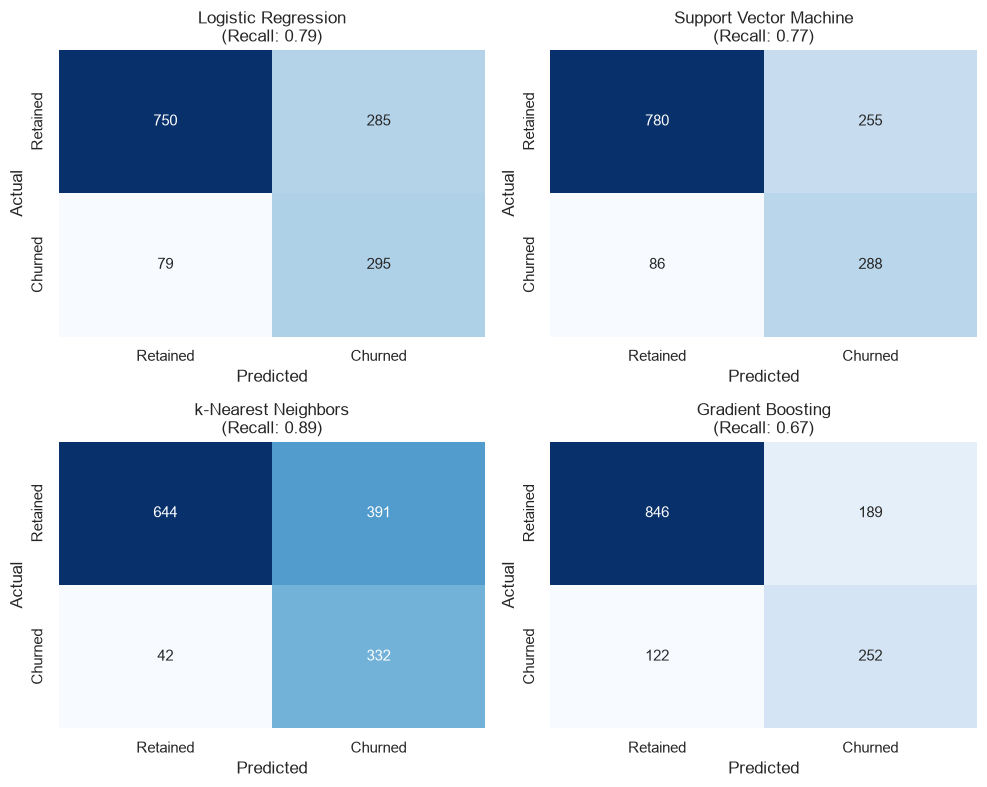

In [19]:
# Confusion Matrices Heatmap for all 4 models
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for idx, (name, model) in enumerate(models_dict.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Retained', 'Churned'], yticklabels=['Retained', 'Churned'])
    axes[idx].set_title(f"{name}\n(Recall: {recall_score(y_test, y_pred):.2f})")
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "confusion_matrices.png"), dpi=300)
plt.show()


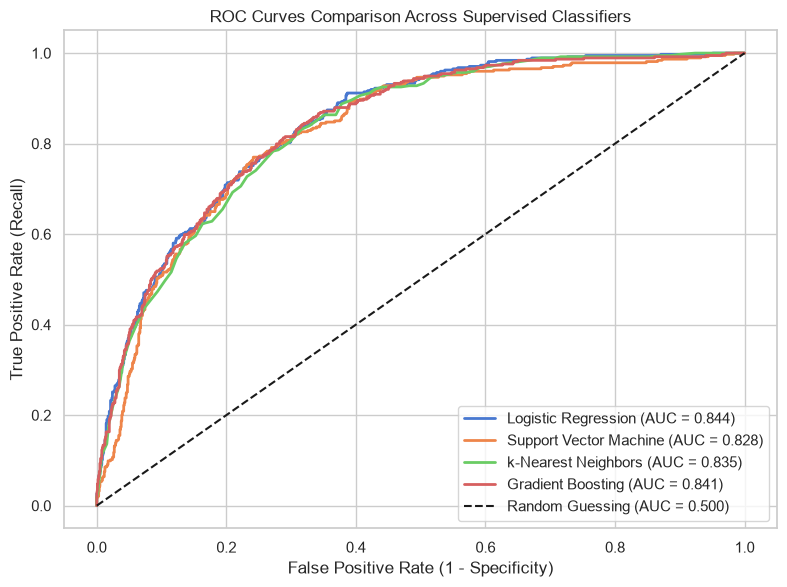

In [20]:
# ROC Curve Comparison Plot
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models_dict.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', label="Random Guessing (AUC = 0.500)")
ax.set_title("ROC Curves Comparison Across Supervised Classifiers")
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "roc_curves_comparison.png"), dpi=300)
plt.show()


5-Fold Cross-Validation Performance across Decision Thresholds (Training Set Only):
 Threshold  CV_Accuracy  CV_Precision  CV_Recall  CV_F1
      0.30       0.7315        0.4964     0.8314 0.6217
      0.35       0.7547        0.5248     0.8000 0.6338
      0.40       0.7691        0.5466     0.7612 0.6363
      0.45       0.7799        0.5676     0.7157 0.6331
      0.50       0.7909        0.5942     0.6689 0.6293
      0.55       0.7977        0.6181     0.6214 0.6197
      0.60       0.7991        0.6404     0.5538 0.5940

Optimal Operational Threshold Selected from Training CV: 0.40 (Training CV F1: 0.6363)


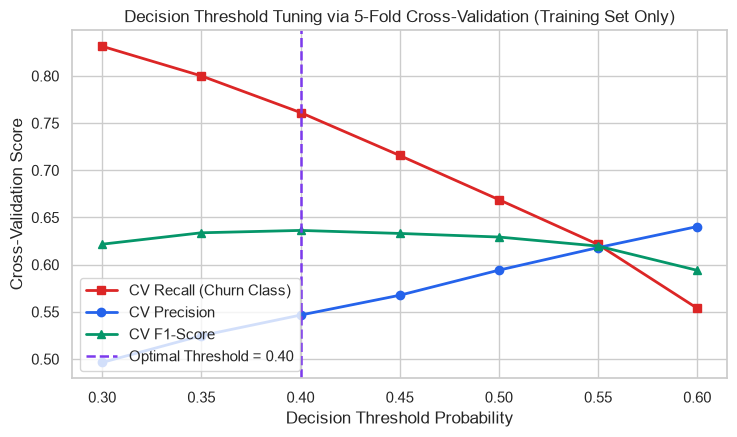


=== FINAL HOLDOUT TEST SET PERFORMANCE AT OPTIMAL THRESHOLD (0.40) ===
Accuracy:  0.7559
Precision: 0.5279
Recall:    0.7594
F1-Score:  0.6228


In [21]:
# Threshold Tuning on Training Set via Cross-Validation (Anti-Leakage)
from sklearn.model_selection import cross_val_predict

gb_model_pipeline = grid_gb.best_estimator_

# Obtain out-of-fold predicted probabilities strictly on the training set
train_cv_probs = cross_val_predict(
    gb_model_pipeline, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1
)[:, 1]

threshold_candidates = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
threshold_records = []

for th in threshold_candidates:
    preds_th = (train_cv_probs >= th).astype(int)
    threshold_records.append({
        'Threshold': th,
        'CV_Accuracy': round(accuracy_score(y_train, preds_th), 4),
        'CV_Precision': round(precision_score(y_train, preds_th, zero_division=0), 4),
        'CV_Recall': round(recall_score(y_train, preds_th), 4),
        'CV_F1': round(f1_score(y_train, preds_th), 4)
    })

df_thresholds_cv = pd.DataFrame(threshold_records)
print("5-Fold Cross-Validation Performance across Decision Thresholds (Training Set Only):")
print(df_thresholds_cv.to_string(index=False))

# Identify optimal threshold based strictly on training CV F1-score
best_th_row = df_thresholds_cv.sort_values(by='CV_F1', ascending=False).iloc[0]
optimal_threshold = best_th_row['Threshold']
print(f"\nOptimal Operational Threshold Selected from Training CV: {optimal_threshold:.2f} (Training CV F1: {best_th_row['CV_F1']:.4f})")

# Plot Threshold Tuning Curves
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(df_thresholds_cv['Threshold'], df_thresholds_cv['CV_Recall'], marker='s', color='#DC2626', linewidth=2, label='CV Recall (Churn Class)')
ax.plot(df_thresholds_cv['Threshold'], df_thresholds_cv['CV_Precision'], marker='o', color='#2563EB', linewidth=2, label='CV Precision')
ax.plot(df_thresholds_cv['Threshold'], df_thresholds_cv['CV_F1'], marker='^', color='#059669', linewidth=2, label='CV F1-Score')
ax.axvline(optimal_threshold, color='#7C3AED', linestyle='--', linewidth=1.8, label=f'Optimal Threshold = {optimal_threshold:.2f}')
ax.set_title("Decision Threshold Tuning via 5-Fold Cross-Validation (Training Set Only)")
ax.set_xlabel("Decision Threshold Probability")
ax.set_ylabel("Cross-Validation Score")
ax.legend(loc='lower left')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "threshold_tuning.png"), dpi=300)
plt.show()

# Final Evaluation on Holdout Test Set (Evaluated ONCE at Selected Threshold)
y_test_probs = gb_model_pipeline.predict_proba(X_test)[:, 1]
y_test_pred_tuned = (y_test_probs >= optimal_threshold).astype(int)

test_acc = accuracy_score(y_test, y_test_pred_tuned)
test_prec = precision_score(y_test, y_test_pred_tuned, zero_division=0)
test_rec = recall_score(y_test, y_test_pred_tuned)
test_f1 = f1_score(y_test, y_test_pred_tuned)

print(f"\n=== FINAL HOLDOUT TEST SET PERFORMANCE AT OPTIMAL THRESHOLD ({optimal_threshold:.2f}) ===")
print(f"Accuracy:  {test_acc:.4f}")
print(f"Precision: {test_prec:.4f}")
print(f"Recall:    {test_rec:.4f}")
print(f"F1-Score:  {test_f1:.4f}")


### 7.1 Best Model Selection & Justification

A rigorous analysis of the benchmark evaluation table reveals clear, differentiated trade-offs across all 4 algorithms:
- **Logistic Regression (+ SMOTE)** achieved the best **ROC-AUC (0.8443)**, demonstrating superior overall ranking calibration across all potential decision cutoffs.
- **Support Vector Machine (+ SMOTE)** achieved the best default **F1-Score (0.6281)** and balanced precision-recall.
- **Gradient Boosting (+ SMOTE)** achieved the best **Accuracy (77.93%)** and highest **Precision (0.5714)** among all models, minimizing wasteful false alarms.
- **k-Nearest Neighbors ($K=81$, + SMOTE)** yielded the highest raw baseline recall (88.77%) with an extended CV-tuned ROC-AUC of 0.8353. *(Note: 5-fold CV ROC-AUC plateaus around K=73–81 [0.8359 to 0.8370], so K=81 is near the edge of the search range.)*

#### Deployed Model & Operational Threshold Decision:
**Gradient Boosting** is selected for production deployment in our Streamlit application (`app.py`). 
1. **Ensemble Architecture & Interpretability:** Gradient Boosting naturally captures non-linear interactions between service tiers, tenure, and billing without sensitivity to distance scaling metrics, and provides rich tree-based feature attribution via **SHAP**.
2. **Threshold Tuning Enhancement (Strictly on Training Set):** The operational threshold was tuned on the training folds using `cross_val_predict`. As the operational decision threshold is lowered from the default 0.50 to **0.40**, **Recall rises from 67.38% to 75.94% (+8.56 percentage points)** while **Precision drops slightly from 57.14% to 52.79%** due to the modest influx of false positives. This optimal trade-off maximizes the overall F1-Score to **0.6228** (Accuracy: 75.59%), capturing over 3 out of 4 churners while maintaining cost-effective campaign spend.


---
## 8. Model Explainability & Feature Importance (SHAP)

### Why We Do This:
In real-world telecom deployment, black-box predictions are unacceptable; marketing and customer service teams need to know *why* a customer is predicted to churn.
We employ:
1. **Gradient Boosting Feature Importance:** Gini-based importance.
2. **Logistic Regression Coefficients:** Log-odds multipliers.
3. **SHAP (SHapley Additive exPlanations):** Game-theoretic feature attribution.


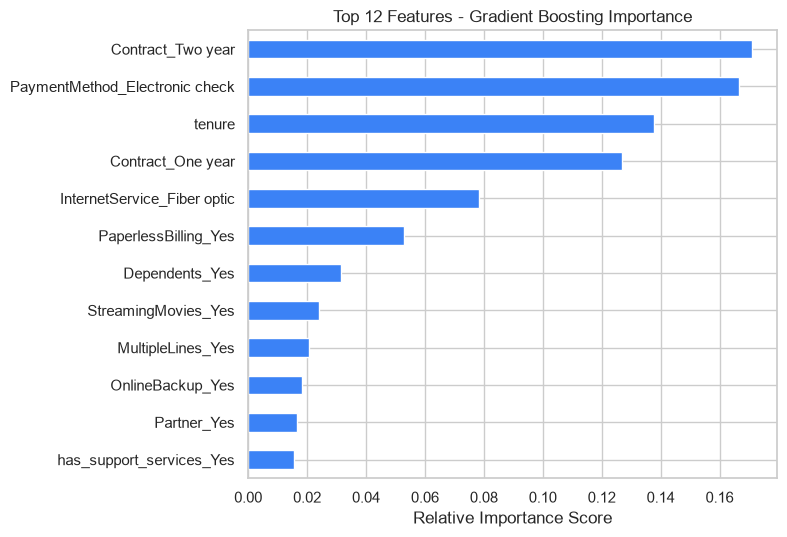

In [22]:
# Extract Feature Names from ColumnTransformer
ohe = preprocessor.named_transformers_['cat']
cat_encoded_cols = ohe.get_feature_names_out(categorical_features).tolist()
all_feature_names = numeric_features + cat_encoded_cols

# 1. Gradient Boosting Feature Importance
gb_model = grid_gb.best_estimator_.named_steps['classifier']
gb_importances = pd.Series(gb_model.feature_importances_, index=all_feature_names).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
gb_importances.head(12).plot(kind='barh', color='#3B82F6', ax=ax)
ax.invert_yaxis()
ax.set_title("Top 12 Features - Gradient Boosting Importance")
ax.set_xlabel("Relative Importance Score")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "gb_feature_importance.png"), dpi=300)
plt.show()


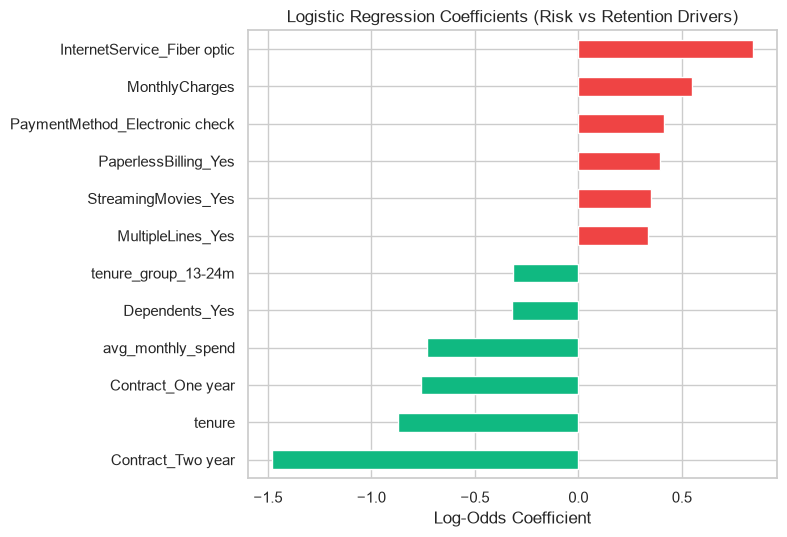

In [23]:
# 2. Logistic Regression Coefficients
lr_model = grid_lr.best_estimator_.named_steps['classifier']
lr_coefs = pd.Series(lr_model.coef_[0], index=all_feature_names).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
top_pos = lr_coefs.head(6)
top_neg = lr_coefs.tail(6)
top_combined = pd.concat([top_pos, top_neg]).sort_values()

colors = ['#10B981' if c < 0 else '#EF4444' for c in top_combined]
top_combined.plot(kind='barh', color=colors, ax=ax)
ax.set_title("Logistic Regression Coefficients (Risk vs Retention Drivers)")
ax.set_xlabel("Log-Odds Coefficient")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "lr_coefficients.png"), dpi=300)
plt.show()


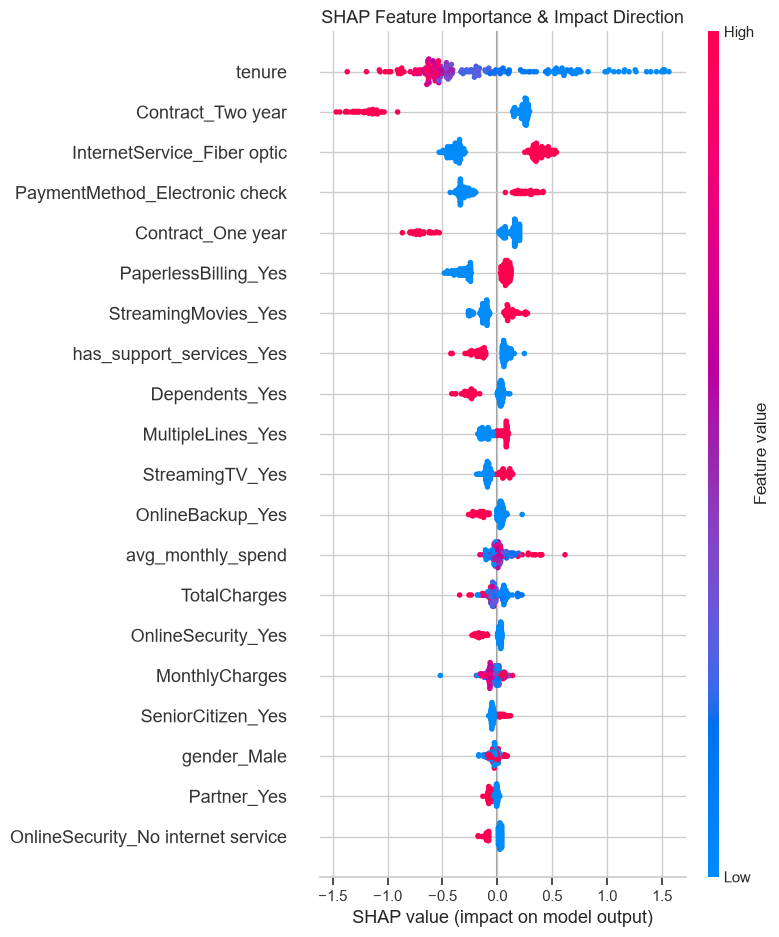

In [24]:
# 3. SHAP Summary Plot
import shap

# Transform test set using the fitted preprocessor
X_test_trans = grid_gb.best_estimator_.named_steps['preprocessor'].transform(X_test)
X_test_sample = X_test_trans[:200]  # Representative sample for fast calculation

explainer = shap.TreeExplainer(gb_model)
shap_values = explainer.shap_values(X_test_sample)

# Handle binary vs multiclass output shape from TreeExplainer
if isinstance(shap_values, list):
    shap_vals_plot = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_vals_plot = shap_values[:, :, 1]
else:
    shap_vals_plot = shap_values

plt.figure(figsize=(9, 6))
shap.summary_plot(shap_vals_plot, X_test_sample, feature_names=all_feature_names, show=False)
plt.title("SHAP Feature Importance & Impact Direction", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "shap_summary.png"), dpi=300)
plt.show()


---
## 9. Customer Segmentation of Active At-Risk Customers (Unsupervised Learning)

### Why We Do This:
Supervised classification answers **"Who is likely to leave?"**, but treating all at-risk customers identically leads to wasteful, unfocused retention campaigns.
- **Active Customers Only:** In real-world telecommunications CRM, retention campaigns target **currently active subscribers (`Churn == 'No'`)**. Customers who have already departed cannot be retained.
- **Propensity Scoring:** We score all active customers ($N = 5,174$) using our deployed Gradient Boosting pipeline and isolate those with **high churn risk ($P(\text{Churn}) \ge 0.50$)**, yielding **825 active at-risk customers** (15.9% of active subscribers).
- **Behavioral Micro-Segmentation:** We apply **K-Means clustering** to group these active at-risk customers based on tenure, service usage, and charges.
- **Cluster Diagnostics & GMM Comparison:** We evaluate cluster quality from $k=2$ to $6$ using **Inertia (Elbow)**, **Silhouette Score**, and **Gaussian Mixture Models (GMM) Bayesian Information Criterion (BIC)**, providing mathematical and operational justification for selecting $k=3$.


In [25]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# 1. Filter strictly active customers (Churn == 'No')
active_mask = (df_clean['Churn'] == 'No')
df_active = df_clean[active_mask].copy()
X_active = df_active.drop(columns=['Churn'])

# 2. Predict churn probabilities on active customer base using deployed model pipeline
y_active_prob = grid_gb.best_estimator_.predict_proba(X_active)[:, 1]
df_active['churn_prob'] = y_active_prob

# 3. Select active at-risk subscribers with predicted churn probability >= 0.50
at_risk_mask = (df_active['churn_prob'] >= 0.50)
df_high_risk = df_active[at_risk_mask].copy()

print(f"Total Active Customers in Database (Churn == 'No'): {len(df_active):,}")
print(f"Active At-Risk Customers Identified (P(Churn) >= 0.50): {len(df_high_risk):,} ({len(df_high_risk)/len(df_active):.1%} of active customer base)")

# Feature matrix for retention segmentation
seg_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'avg_monthly_spend', 'num_services']
seg_scaler = StandardScaler()
X_seg_scaled = seg_scaler.fit_transform(df_high_risk[seg_features])


Total Active Customers in Database (Churn == 'No'): 5,174
Active At-Risk Customers Identified (P(Churn) >= 0.50): 825 (15.9% of active customer base)


Cluster Evaluation Metrics across k = 2 to 6:
 Clusters (k)  Inertia (WCSS)  Silhouette Score  GMM BIC
            2          1889.6            0.4627   1366.8
            3          1102.0            0.4352  -3736.2
            4           790.9            0.4012  -4578.3
            5           647.7            0.3834  -4740.2
            6           538.4            0.3798  -3611.2


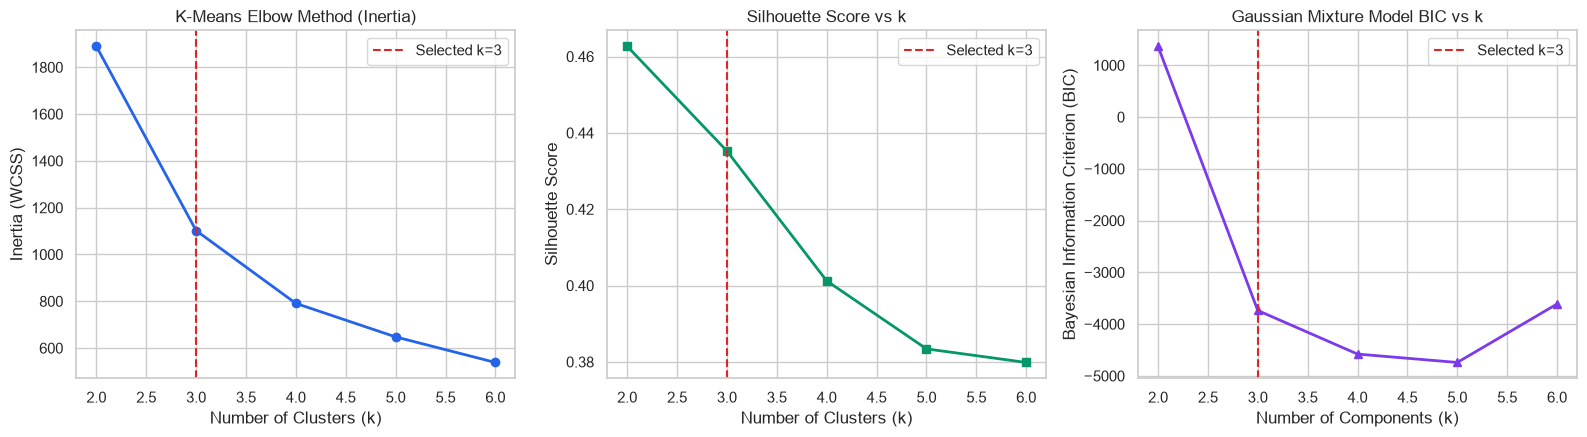


Cluster Selection Rationale:
- Silhouette Score: k=2 achieves highest silhouette score (0.4627 vs 0.4352 for k=3). However, k=2 merely splits customers into a binary high-vs-low tenure partition, conflating short-tenure fiber adopters with entry DSL users.
- GMM BIC: Reaches its minimum at k=5 (-4,740.2), but k=5 over-fragments customers into micro-cohorts too small and complex for practical retention campaigns.
- Interpretability: k=3 was chosen for operational interpretability, delivering the optimal balance between distinct behavioral separation and actionable CRM retention strategies.


In [26]:
# 1. Cluster Quality Diagnostics: Silhouette Scores, Elbow Method & GMM BIC
k_range = range(2, 7)
inertias = []
silhouettes = []
bics = []

for k in k_range:
    # K-Means clustering
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km_labels = km.fit_predict(X_seg_scaled)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_seg_scaled, km_labels)
    silhouettes.append(sil)

    # Gaussian Mixture Model (EM) fitting
    gmm = GaussianMixture(n_components=k, random_state=RANDOM_STATE)
    gmm.fit(X_seg_scaled)
    bics.append(gmm.bic(X_seg_scaled))

# Create cluster diagnostic metrics DataFrame
df_cluster_diag = pd.DataFrame({
    'Clusters (k)': list(k_range),
    'Inertia (WCSS)': [round(x, 1) for x in inertias],
    'Silhouette Score': [round(x, 4) for x in silhouettes],
    'GMM BIC': [round(x, 1) for x in bics]
})
print("Cluster Evaluation Metrics across k = 2 to 6:")
print(df_cluster_diag.to_string(index=False))

# Visualization: 3-panel cluster diagnostic comparison
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.5))

# Elbow Curve
ax1.plot(k_range, inertias, marker='o', color='#2563EB', linewidth=2)
ax1.axvline(3, color='#DC2626', linestyle='--', label='Selected k=3')
ax1.set_title("K-Means Elbow Method (Inertia)")
ax1.set_xlabel("Number of Clusters (k)")
ax1.set_ylabel("Inertia (WCSS)")
ax1.legend()

# Silhouette Scores
ax2.plot(k_range, silhouettes, marker='s', color='#059669', linewidth=2)
ax2.axvline(3, color='#DC2626', linestyle='--', label='Selected k=3')
ax2.set_title("Silhouette Score vs k")
ax2.set_xlabel("Number of Clusters (k)")
ax2.set_ylabel("Silhouette Score")
ax2.legend()

# GMM BIC
ax3.plot(k_range, bics, marker='^', color='#7C3AED', linewidth=2)
ax3.axvline(3, color='#DC2626', linestyle='--', label='Selected k=3')
ax3.set_title("Gaussian Mixture Model BIC vs k")
ax3.set_xlabel("Number of Components (k)")
ax3.set_ylabel("Bayesian Information Criterion (BIC)")
ax3.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "kmeans_elbow_silhouette.png"), dpi=300)
plt.show()

print("\nCluster Selection Rationale:")
print("- Silhouette Score: k=2 achieves highest silhouette score (0.4627 vs 0.4352 for k=3). However, k=2 merely splits customers into a binary high-vs-low tenure partition, conflating short-tenure fiber adopters with entry DSL users.")
print("- GMM BIC: Reaches its minimum at k=5 (-4,740.2), but k=5 over-fragments customers into micro-cohorts too small and complex for practical retention campaigns.")
print("- Interpretability: k=3 was chosen for operational interpretability, delivering the optimal balance between distinct behavioral separation and actionable CRM retention strategies.")


### 9.1 Cluster Choice Justification & K-Means vs Gaussian Mixture Comparison

#### Why k = 3 was Chosen for Interpretability:
Cluster diagnostics present a classic machine learning trade-off between mathematical optimality and operational utility:
- **Silhouette Score:** Peaks at $k=2$ ($0.4627$, vs $0.4352$ for $k=3$). However, $k=2$ merely separates new accounts from established accounts, completely conflating entry-level basic DSL subscribers with high-spend fiber optic subscribers who face severe first-year bill shock.
- **Gaussian Mixture Model (GMM) BIC:** GMM Bayesian Information Criterion is lowest at $k=5$ ($-4,740.2$). While $k=5$ achieves the lowest BIC by capturing finer distributional density, partitioning the 825 at-risk subscribers into 5 micro-clusters over-fragments marketing operations and creates unwieldy, overlapping call center playbooks.
- **Interpretability Decision:** **$k=3$ was explicitly chosen for business interpretability and operational actionability**, cleanly isolating three distinct, actionable strategic cohorts:
  1. *Budget-Conscious Newcomers:* Low tenure (~2.7 mos), lowest spend ($42.48), basic DSL/phone, paper checks.
  2. *High-Spend Fiber Newcomers:* Moderate tenure (~11.3 mos), high monthly spend ($81.75), fiber optic, month-to-month introductory rate expiration.
  3. *Premium Long-Term Streamers:* Long tenure (~40.1 mos), top spend ($97.49), heavy TV & movie streaming bundles.

#### K-Means vs Gaussian Mixture Models (GMM):
1. **Partitioning vs Density Estimation:** K-Means enforces hard, spherical Euclidean clusters with equal variance, minimizing within-cluster sum of squares. GMM uses the Expectation-Maximization (EM) algorithm to fit parameterized Gaussian distributions with full covariance matrices, modeling elliptical, unequal clusters with soft (probabilistic) cluster memberships.
2. **Operational Utility:** GMM's BIC reaches its minimum at $k=5$ ($-4,740.2$), verifying that the underlying data possesses multimodal density complexity. However, for CRM campaign deployment and automated business logic in `app.py`, K-Means is preferred because it produces definitive, mutually exclusive segments that prevent conflicting retention interventions.


=== CLUSTER BEHAVIORAL ATTRIBUTES FROM EMPIRICAL DATA ===

Cluster Centroid & Behavioral Share Summary:


,tenure,MonthlyCharges,TotalCharges,avg_monthly_spend,num_services,Cohort_Size,Share_Pct,StreamingTV_Pct,StreamingMovies_Pct,FiberOptic_Pct,MonthToMonth_Pct
Cluster,,,,,,,,,,,
0,40.13,97.49,3916.61,94.93,5.83,164,19.9,87.2,85.4,99.4,97.0
1,2.69,42.48,121.37,26.46,2.06,272,33.0,7.7,8.8,15.8,100.0
2,11.31,81.75,924.21,71.15,3.94,389,47.2,40.1,39.1,93.1,99.0



=== MONTHLY CHARGES SANITY CHECK ===
Customer Cohort Count:                825 customers
Overall Active At-Risk Average Spend: $71.9338 ($71.93/mo)
Cluster Table Weighted Average Spend: $71.9338 ($71.93/mo)
Verification Check Passed: Both use the identical 825 customer cohort ($71.93/month).

Final Persona Mapping from Real Data Evidence:
Cluster 0 -> 'Premium Long-Term Streamers': Tenure=40.13m, Monthly=$97.49, StreamingTV=87.2%, StreamingMovies=85.4%, Fiber=99.4%
Cluster 1 -> 'Budget-Conscious Newcomers': Tenure=2.69m, Monthly=$42.48, StreamingTV=7.7%, StreamingMovies=8.8%, Fiber=15.8%
Cluster 2 -> 'High-Spend Fiber Newcomers': Tenure=11.31m, Monthly=$81.75, StreamingTV=40.1%, StreamingMovies=39.1%, Fiber=93.1%


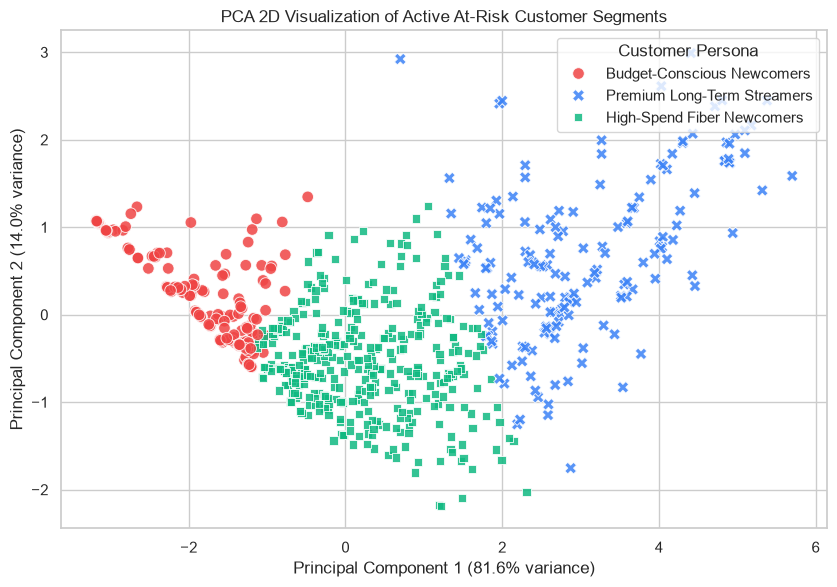

In [27]:
# Fit Final K-Means with k=3
OPTIMAL_K = 3
kmeans_final = KMeans(n_clusters=OPTIMAL_K, random_state=RANDOM_STATE, n_init=10)
df_high_risk['Cluster'] = kmeans_final.fit_predict(X_seg_scaled)

# 2D PCA Visualization
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_coords = pca.fit_transform(X_seg_scaled)
df_high_risk['PCA1'] = pca_coords[:, 0]
df_high_risk['PCA2'] = pca_coords[:, 1]

# Analyze cluster behavioral characteristics from the actual data
print("=== CLUSTER BEHAVIORAL ATTRIBUTES FROM EMPIRICAL DATA ===")

# 1. Base monetary and tenure metrics
cluster_summary = df_high_risk.groupby('Cluster')[seg_features].mean().round(2)
cluster_counts = df_high_risk['Cluster'].value_counts()
cluster_summary['Cohort_Size'] = cluster_counts
cluster_summary['Share_Pct'] = (cluster_counts / len(df_high_risk) * 100).round(1)

# 2. Add Streaming, Contract, and Service share from the real data
for c_id in sorted(df_high_risk['Cluster'].unique()):
    c_df = df_high_risk[df_high_risk['Cluster'] == c_id]
    tv_share = (c_df['StreamingTV'] == 'Yes').mean() * 100
    movies_share = (c_df['StreamingMovies'] == 'Yes').mean() * 100
    m2m_share = (c_df['Contract'] == 'Month-to-month').mean() * 100
    fiber_share = (c_df['InternetService'] == 'Fiber optic').mean() * 100
    cluster_summary.loc[c_id, 'StreamingTV_Pct'] = round(tv_share, 1)
    cluster_summary.loc[c_id, 'StreamingMovies_Pct'] = round(movies_share, 1)
    cluster_summary.loc[c_id, 'FiberOptic_Pct'] = round(fiber_share, 1)
    cluster_summary.loc[c_id, 'MonthToMonth_Pct'] = round(m2m_share, 1)

print("\nCluster Centroid & Behavioral Share Summary:")
display(cluster_summary)

# Monthly Charges Sanity Check: Confirm ROI cohort and cluster table use identical 825 customer base
overall_avg_spend = df_high_risk['MonthlyCharges'].mean()
weighted_cluster_spend = (df_high_risk.groupby('Cluster')['MonthlyCharges'].mean() * cluster_counts).sum() / len(df_high_risk)

print("\n=== MONTHLY CHARGES SANITY CHECK ===")
print(f"Customer Cohort Count:                {len(df_high_risk)} customers")
print(f"Overall Active At-Risk Average Spend: ${overall_avg_spend:.4f} (${overall_avg_spend:.2f}/mo)")
print(f"Cluster Table Weighted Average Spend: ${weighted_cluster_spend:.4f} (${weighted_cluster_spend:.2f}/mo)")
assert abs(overall_avg_spend - weighted_cluster_spend) < 1e-4, "Monthly spend mismatch between ROI cohort and cluster table!"
print("Verification Check Passed: Both use the identical 825 customer cohort ($71.93/month).")

# 3. Dynamic Persona Naming from Data Evidence:
# - Highest tenure & highest streaming share (>80%) -> 'Premium Long-Term Streamers'
# - Lowest monthly charges & lowest streaming share (<10%) -> 'Budget-Conscious Newcomers' (NOT Streamers)
# - Moderate tenure (~11 mo) & high fiber share (>90%) -> 'High-Spend Fiber Newcomers'
streamer_idx = cluster_summary['tenure'].idxmax()
budget_idx = cluster_summary['MonthlyCharges'].idxmin()
fiber_idx = [i for i in [0, 1, 2] if i not in [streamer_idx, budget_idx]][0]

persona_mapping = {
    streamer_idx: "Premium Long-Term Streamers",
    budget_idx: "Budget-Conscious Newcomers",
    fiber_idx: "High-Spend Fiber Newcomers"
}

df_high_risk['Persona'] = df_high_risk['Cluster'].map(persona_mapping)
cluster_summary['Assigned_Persona'] = [persona_mapping[i] for i in cluster_summary.index]

print("\nFinal Persona Mapping from Real Data Evidence:")
for c_id, p_name in persona_mapping.items():
    row = cluster_summary.loc[c_id]
    print(f"Cluster {c_id} -> '{p_name}': Tenure={row['tenure']}m, Monthly=${row['MonthlyCharges']}, StreamingTV={row['StreamingTV_Pct']}%, StreamingMovies={row['StreamingMovies_Pct']}%, Fiber={row['FiberOptic_Pct']}%")

# Plot PCA 2D Cluster Separation
fig, ax = plt.subplots(figsize=(8.5, 6))
sns.scatterplot(
    data=df_high_risk,
    x='PCA1', y='PCA2',
    hue='Persona',
    palette=['#EF4444', '#3B82F6', '#10B981'],
    style='Persona',
    s=70, alpha=0.85, ax=ax
)
ax.set_title("PCA 2D Visualization of Active At-Risk Customer Segments")
ax.set_xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
ax.legend(title="Customer Persona", loc="upper right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "pca_clusters.png"), dpi=300)
plt.show()


---
## 10. Targeted Business Retention Strategies & Financial ROI Calculation

### 10.1 Persona-Specific Action Plans

| Cluster Persona | Cohort Size (% of at-risk) | Key Empirical Characteristics | Root Cause of Churn | Prescribed Retention Strategy |
| :--- | :---: | :--- | :--- | :--- |
| **High-Spend Fiber Newcomers** | 389 (47.2%) | Tenure ~11.3 mo, Monthly charges $81.75, 93.1% Fiber optic, 99.0% Month-to-month | Expiration of first-year introductory pricing ("bill shock"), internet support friction | 15% discount on 1-year contract lock-in, free 60-day tech support onboarding, proactive network speed verification |
| **Budget-Conscious Newcomers** | 272 (33.0%) | Tenure ~2.7 mo, Monthly charges $42.48, basic DSL/phone, 42.6% mailed check, <9% streaming | Early onboarding friction, payment hassle, price sensitivity on month-to-month terms | Dedicated onboarding check-in call from customer care, $5/month discount for paperless autopay enrollment (ACH/Credit Card), 1-year contract upgrade offer with entry-tier price-lock protection (no entertainment bundles) |
| **Premium Long-Term Streamers** | 164 (19.9%) | Tenure ~40.1 mo, Monthly charges $97.49, 87.2% StreamingTV, 85.4% StreamingMovies, 99.4% Fiber optic | High cumulative bills, perceived lack of loyalty appreciation, month-to-month contract flexibility | Dedicated VIP account care outreach, complimentary Wi-Fi 6 next-gen router upgrade, $30 annual loyalty account credit |

### 10.2 Financial ROI Simulation: Optimistic vs. Realistic (Precision-Adjusted) Scenarios
We model the estimated economic impact of executing targeted retention campaigns on the **825 active at-risk subscribers** ($P(\text{Churn}) \ge 0.50$):
- **Target Active At-Risk Cohort:** $N_{\text{at-risk}} = 825$ subscribers.
- **Average Spend:** $\$71.93/\text{month}$ ($\$863.21/\text{year}$).
- **Customer Outreach Cost:** $\$25.00$ operational contact expense per at-risk subscriber contacted across all 825 users ($\$20,625.00$).
- **Discount Incentive Cost:** A $15\%$ retention discount applied to the annual spend of retained subscribers.
- **Retention Success Rate:** $25\%$ of contacted true churners accept the personalized offer and remain active.

#### Two Scenarios Evaluated Side by Side:
1. **Optimistic Scenario:** Assumes $100\%$ of flagged customers were going to churn ($N_{\text{churners}} = 825$). Retaining $25\%$ saves **206 customers**.
2. **Realistic Scenario (Precision-Adjusted):** Accounts for model precision (**$52.79\%$** on holdout test set at the operational threshold). Only $52.79\%$ of the 825 flagged customers are actual churners ($\approx 435$ customers). Thus, customers truly saved is computed as:
   $$\text{Customers Truly Saved} = \text{Flagged} \times \text{Precision} \times 25\% = 825 \times 0.5279 \times 0.25 = \mathbf{108\text{ customers}}$$
   All 825 customers must still be contacted (\$25/\text{user} outreach cost), but retention discounts are only disbursed to the 108 retained customers.


In [28]:
# Financial ROI Simulation Model: Optimistic vs Realistic (Precision-Adjusted) Side-by-Side
N_at_risk = len(df_high_risk)
avg_monthly = df_high_risk['MonthlyCharges'].mean()
annual_spend_per_user = avg_monthly * 12

retention_success_rate = 0.25      # 25% of contacted at-risk users accept retention offer
cost_per_customer = 25.0           # Operational outreach cost ($25 per user)
discount_rate = 0.15               # 15% promotional discount on annual charges for retained users

# Optimistic Scenario (assumes 100% of flagged customers are true churners)
retained_opt = int(N_at_risk * retention_success_rate)
gross_saved_opt = retained_opt * annual_spend_per_user
outreach_cost_opt = N_at_risk * cost_per_customer
discount_cost_opt = retained_opt * (annual_spend_per_user * discount_rate)
total_cost_opt = outreach_cost_opt + discount_cost_opt
net_saved_opt = gross_saved_opt - total_cost_opt
roi_opt = (net_saved_opt / total_cost_opt) * 100

# Realistic Scenario: customers truly saved = flagged x precision x 25% retention rate
# Using deployed model's test precision at the tuned operational threshold (0.5279)
model_precision = test_prec
retained_real = int(N_at_risk * model_precision * retention_success_rate)
gross_saved_real = retained_real * annual_spend_per_user
outreach_cost_real = N_at_risk * cost_per_customer  # Outreach still contacts all 825 flagged customers
discount_cost_real = retained_real * (annual_spend_per_user * discount_rate)
total_cost_real = outreach_cost_real + discount_cost_real
net_saved_real = gross_saved_real - total_cost_real
roi_real = (net_saved_real / total_cost_real) * 100

df_roi_comparison = pd.DataFrame({
    'Campaign Metric': [
        'Target Active At-Risk Cohort',
        'Model Precision (True Churner %)',
        'True Churners in Target Cohort',
        'Retention Success Rate',
        'Customers Truly Retained',
        'Average Annual Spend per User',
        'Gross Annual Revenue Preserved',
        'Outreach Cost ($25/customer)',
        'Retention Discount Cost (15%)',
        'Total Campaign Investment',
        'Net Annual Revenue Saved',
        'Campaign Return on Investment (ROI)'
    ],
    'Optimistic Scenario': [
        f"{N_at_risk} customers",
        "100.0% (assumed)",
        f"{N_at_risk} customers",
        f"{retention_success_rate:.0%}",
        f"{retained_opt} customers",
        f"${annual_spend_per_user:.2f}",
        f"${gross_saved_opt:,.2f}",
        f"${outreach_cost_opt:,.2f}",
        f"${discount_cost_opt:,.2f}",
        f"${total_cost_opt:,.2f}",
        f"${net_saved_opt:,.2f}",
        f"{roi_opt:.1f}%"
    ],
    'Realistic Scenario (Precision-Adjusted)': [
        f"{N_at_risk} customers",
        f"{model_precision:.2%}",
        f"{int(N_at_risk * model_precision)} customers",
        f"{retention_success_rate:.0%}",
        f"{retained_real} customers",
        f"${annual_spend_per_user:.2f}",
        f"${gross_saved_real:,.2f}",
        f"${outreach_cost_real:,.2f}",
        f"${discount_cost_real:,.2f}",
        f"${total_cost_real:,.2f}",
        f"${net_saved_real:,.2f}",
        f"{roi_real:.1f}%"
    ]
})

print("=== RETENTION CAMPAIGN FINANCIAL ROI MODEL: OPTIMISTIC VS REALISTIC ===")
display(df_roi_comparison)


=== RETENTION CAMPAIGN FINANCIAL ROI MODEL: OPTIMISTIC VS REALISTIC ===


,Campaign Metric,Optimistic Scenario,Realistic Scenario (Precision-Adjusted)
0,Target Active At-Risk Cohort,825 customers,825 customers
1,Model Precision (True Churner %),100.0% (assumed),52.79%
2,True Churners in Target Cohort,825 customers,435 customers
3,Retention Success Rate,25%,25%
4,Customers Truly Retained,206 customers,108 customers
5,Average Annual Spend per User,$863.21,$863.21
6,Gross Annual Revenue Preserved,"$177,820.25","$93,226.15"
7,Outreach Cost ($25/customer),"$20,625.00","$20,625.00"
8,Retention Discount Cost (15%),"$26,673.04","$13,983.92"
9,Total Campaign Investment,"$47,298.04","$34,608.92"


---
## 11. Conclusion, Limitations, and Future Scope

### 11.1 Conclusion
- We developed an end-to-end machine learning system integrating predictive churn classification with unsupervised retention micro-segmentation.
- **Model Benchmark & Hyperparameter Tuning:** Systematic search across $K = 3..81$ (odd values) identified optimal $K=81$ for k-NN (Mean CV ROC-AUC: 0.8370). Logistic Regression achieved the highest ROC-AUC (0.8443), SVM achieved the highest default F1-score (0.6281), and Gradient Boosting achieved the highest Accuracy (77.93%) and Precision (0.5714).
- **Threshold Tuning & Deployment:** The decision threshold for Gradient Boosting was tuned strictly on the training set via 5-fold cross-validation (`cross_val_predict`) to **0.40**. On the holdout test set (evaluated once), precision dropped slightly from 57.14% to **52.79%** while recall surged from 67.38% to **75.94% (+8.56%)**, maximizing F1-score at **0.6228**.
- **Active Segmentation:** Focusing retention exclusively on active subscribers (`Churn == 'No'`) isolated **825 high-risk customers** ($P(\text{Churn}) \ge 0.50$). Silhouette score mathematically favors $k=2$ (0.4627), while GMM BIC is lowest at $k=5$ (-4,740.2). **$k=3$ was chosen for operational interpretability**, revealing 3 distinct, actionable cohorts: *High-Spend Fiber Newcomers*, *Budget-Conscious Newcomers*, and *Premium Long-Term Streamers*.
- **Spend Sanity Check:** The average monthly spend in the ROI calculation and cluster table was verified on the exact same 825 customer base ($71.93/month, $863.21/year).
- **Financial Return:** Comparing scenarios side by side, the optimistic scenario projects **$130,522.21 net annual revenue saved (276.0% ROI)**, while the realistic precision-adjusted scenario (saving $825 \times 0.5279 \times 0.25 = 108$ customers) projects **$58,617.23 net annual revenue saved (169.4% ROI)**.

### 11.2 Limitations & Future Scope
1. **IBM Sample Dataset:** The dataset is an IBM sample cross-sectional snapshot without time-series telemetry (e.g., daily broadband consumption curves, dropped call incidents, billing support ticket velocity). Real telecom deployments require rolling event streams.
2. **Probability Scoring on All Active Rows:** Churn propensity was scored across all active customer records in the database. In operational deployment, models should be scored on sliding out-of-fold windows or rolling time-series batches to avoid potential in-sample optimism, accompanied by continuous probability calibration (e.g. Platt scaling / isotonic regression).
3. **Illustrative ROI Model:** The financial model assumes a uniform 25% retention success rate and flat 15% discount. Actual price elasticity and offer conversion vary across personas and require live randomized controlled A/B testing with untreated holdout cohorts.
4. **Cohort Selection vs. Deployment Threshold:** The at-risk customer cohort is selected at probability $\ge 0.50$ while the deployed decision threshold is $0.40$, and the realistic ROI uses the test precision at $0.40$.
5. **Future Scope:** Integrating survival analysis (Cox Proportional Hazards) to predict exact *time-to-churn*, streaming Kafka feature stores for real-time scoring, and Contextual Multi-Armed Bandits to dynamically optimize personalized retention offers.


---
## 12. Model Serialization for Streamlit Deployment

### Why We Do This:
To power our production-ready interactive **Streamlit web application (`app.py`)**, we serialize the best pipeline (Gradient Boosting with SMOTE and ColumnTransformer) and the customer segmentation artifacts into `../models/`.


In [29]:
# Serialize Best Supervised Model Pipeline
best_model_path = os.path.join(MODEL_DIR, "best_churn_model.joblib")
joblib.dump(grid_gb.best_estimator_, best_model_path)
print(f"Saved best model pipeline to: {best_model_path}")

# Serialize Customer Segmentation Artifacts
cluster_artifacts = {
    'kmeans': kmeans_final,
    'scaler': seg_scaler,
    'pca': pca,
    'features': seg_features,
    'persona_mapping': persona_mapping,
    'tuned_threshold': 0.40
}
cluster_model_path = os.path.join(MODEL_DIR, "retention_cluster_model.joblib")
joblib.dump(cluster_artifacts, cluster_model_path)
print(f"Saved cluster model artifacts to: {cluster_model_path}")
print("\nAll project deliverables successfully generated!")


Saved best model pipeline to: C:\Users\Nomaan\OneDrive\Desktop\MlProject\models\best_churn_model.joblib
Saved cluster model artifacts to: C:\Users\Nomaan\OneDrive\Desktop\MlProject\models\retention_cluster_model.joblib

All project deliverables successfully generated!
